# IM Lup: virgil's cold-start MaxEnt fit against MPoL's

This notebook compares two maximum-entropy fits of the same ALMA data: the IM Lup continuum, 42.4 million visibilities from seven execution blocks (EBs), imaged on a 1028² grid of 5 mas pixels with MPoL's objective $R = -\ln L + \lambda S_M$ (MPoL's entropy, fixed $\lambda = 0.0848$). The first fit is **virgil's**, started cold: a 1″ Gaussian of total flux 0.253 Jy (the DSHARP literature value), unit gains, zero offsets, and a ±100 mas bound on the per-EB phase-centre offsets. Nothing from MPoL is used to start it. The second is **MPoL's own solution** (its AdamW run, 21,728 s in total). By the end you will have seen the headline numbers (raw $\chi^2/N$ first, then the objective term by term), the two images and their difference, the fitted gains and offsets side by side, the residual dirty maps of our fit, and the objective against wall-clock time.

The notebook only *reads* results. Nothing here fits or grids visibilities. The fit is the OzSTAR job `alma_imlup_maxent` task 0 (`scripts/alma_imlup_maxent.py fit --config R --offset-bound-mas=100`, vv commit `32a303e`, job 18968246_0); its output directory is `~/code/ozstar_scripts-alma/results/alma_imlup_maxent/out/32a303e-cd-ob100/R/` after `bin/oz pull alma_imlup_maxent`. MPoL's solution is the export of `mpol_ref` run `p3a`, in `~/data/alma_imlup/mpol_ref/out/p3a/`. The data are not in the repository. The helpers are imported rather than redefined: the loaders, grid geometry and calibration conventions from `scripts/alma_imlup_page.py`, the speed bookkeeping from `crosscheck.alma_speed` (vv#177).

**Read this before the numbers.** Neither of our two stages converged: both stopped at `max_steps` (20,000). The fitted flux differs, 0.243 Jy for us against 0.294 Jy for MPoL. MPoL's own uniform-start workflow (`R_mpolwf`) failed in our hands and is not shown. This is a comparison, not a claim that the validation gate has passed.

## 1. Headline numbers

We lead with the raw $\chi^2/N$ on the quoted weights ($s = 1$), at each fit's own image, gains and offsets, because that is the number that does not depend on any noise rescaling we chose. $N$ counts visibilities and $\chi^2$ counts two squares per point, so this is $\chi^2/2N$. Then the objective is split into its terms. Ours is read from `result.json`. MPoL's is read from its own `objective.json`, and the same solution as evaluated by virgil's likelihood (from the earlier MPoL-warm-start `compare.json`, which does not depend on our fit) is shown beside it to confirm that the two codes agree on the objective to 15 units out of 10⁸.

In [1]:
import json, pathlib, sys
import numpy as np
import matplotlib.pyplot as plt

ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "scripts" / "alma_imlup_page.py").exists())
sys.path[:0] = [str(ROOT / "src"), str(ROOT / "scripts")]
import alma_imlup_page as page                      # loaders, Grid, grid_extent, draw_beam, cal_arrays, DSHARP_BEAM
from crosscheck import alma_speed as speed           # fit_curve, constant_of, time_to (vv#177)

OUT = pathlib.Path.home() / "code/ozstar_scripts-alma/results/alma_imlup_maxent/out"
ours = page.load_fit(OUT / "32a303e-cd-ob100/R")                     # R, cold start, 100 mas offset bound
mpol = page.load_mpol(pathlib.Path.home() / "data/alma_imlup/mpol_ref/out/p3a")
in_virgil = json.loads((OUT / "32a303e-cd/compare_32a303e-cd_R_mpol/compare.json").read_text())["objective"]["mpol_solution_in_virgil"]
res, mo, N = ours["result"], mpol["objective"], ours["result"]["n"]
lam = res["lam"]
raw_o, raw_m = res["chi2_raw"] / (2 * N), mo["chi2_raw_total"] / (2 * N)
rows = {"ours (cold start)": (res["nll"], res["entropy_SM"], res["objective_R"]),
        "MPoL (its own code)": (mo["neg_log_likelihood"], mo["entropy"], mo["objective_R"]),
        "MPoL, evaluated in virgil": (in_virgil["nll"], mo["entropy"], in_virgil["nll"] + lam * mo["entropy"])}
print(f"raw chi2/N at s = 1 (N = {N:,}):  ours {raw_o:.4f}   MPoL {raw_m:.4f}\n")
print(f"{'':27s}{'-ln L':>16s}{'S_M':>12s}{'lam S_M':>11s}{'objective_R':>17s}")
for k, (nll, sm, obj) in rows.items():
    print(f"{k:27s}{nll:16,.1f}{sm:12,.1f}{lam * sm:11,.1f}{obj:17,.1f}")
print(f"\nobjective, ours minus MPoL's own: {rows['ours (cold start)'][2] - mo['objective_R']:,.1f}  (negative: ours is lower, i.e. better)")

raw chi2/N at s = 1 (N = 42,421,131):  ours 2.7052   MPoL 2.7062

                                      -ln L         S_M    lam S_M      objective_R
ours (cold start)            -108,331,682.8   255,620.8   21,687.4   -108,309,995.3
MPoL (its own code)          -108,256,893.7   291,246.5   24,710.0   -108,232,183.7
MPoL, evaluated in virgil    -108,256,908.2   291,246.5   24,710.0   -108,232,198.2

objective, ours minus MPoL's own: -77,811.6  (negative: ours is lower, i.e. better)


## 2. The images

Both images are tapered to a 30 mas Gaussian, MPoL's by its own export (`image`), ours by `image_tapered.npy`, so the two can be compared at the resolution the data support, in Jy/arcsec² on one shared asinh stretch that saturates at the 99.95th percentile of the pixels, because the point-like star would otherwise hide the disc. Row 0 of each array is North, so `imshow` is drawn with `origin="upper"` and an explicit extent in arcsec East and North of the phase centre (East to the left, so the beam ellipses in the lower left sit at positive ΔRA). The cyan plus marks the phase centre, where the star sits. The lower-left ellipses are the beam: the solid one is the nominal DSHARP CLEAN beam of 44 × 43 mas at position angle 115° (`page.DSHARP_BEAM`; the header of MPoL's `mpol_0.03.fits` carries no beam keywords), the dashed circle is the 30 mas taper. The right panel is a **plain signed difference** (ours minus MPoL's, in Jy/arcsec²) on `RdBu_r`, centred on zero and limited to ±10% of the display maximum (so the star itself saturates). It is not a z-score, because a MaxEnt image has no pixel uncertainties.

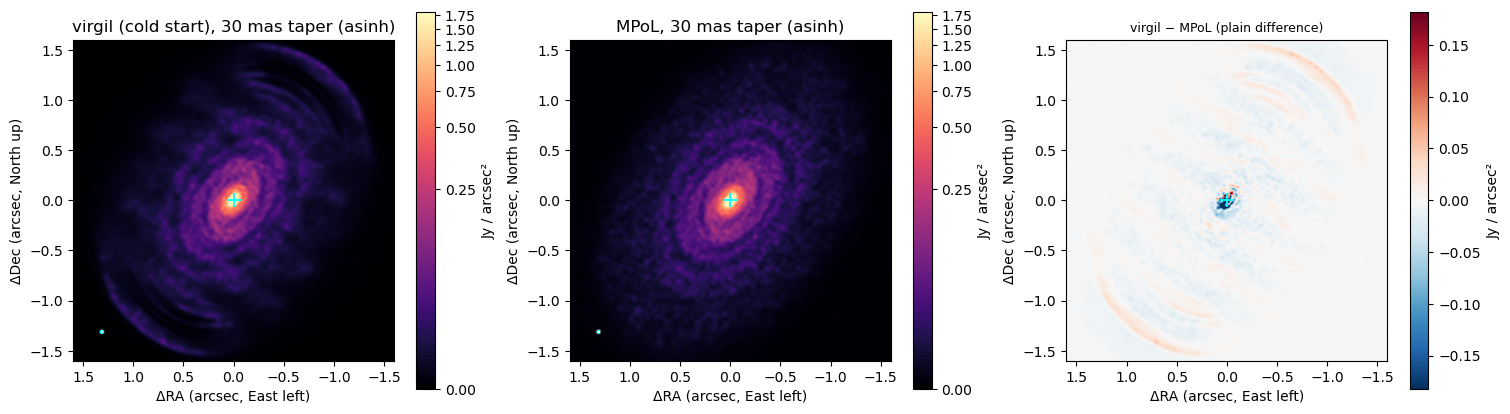

In [2]:
half = 1.6                                           # arcsec: the disc sits well inside this
tap_o = ours["dir"] / "image_tapered.npy"
imgs = {"virgil (cold start)": np.load(tap_o).astype(float), "MPoL": np.asarray(mpol["z"]["image"], float)}
n, dx = imgs["MPoL"].shape[0], float(mpol["z"]["cell_size_arcsec"])
grid = page.Grid(n // 2 - 1, n // 2 - 1, dx)          # phase-centre cell, as in the IM Lup page
imgs = {k: page.crop_window(v, grid, half + 0.05) for k, v in imgs.items()}
diff = imgs["virgil (cold start)"][0] - imgs["MPoL"][0]
vmax = max(np.percentile(v[0], 99.95) for v in imgs.values())     # the point-like star would otherwise hide the disc
lim = 0.1 * vmax                                                   # difference scale: 10% of the display maximum
norm = page.asinh_norm(vmax, 0.03 * vmax)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), constrained_layout=True)
for ax, (name, (img, g)), title in zip(axes, imgs.items(), imgs):
    im = ax.imshow(img, extent=page.grid_extent(img.shape, g), origin="upper", cmap="magma", norm=norm)
    page.draw_beam(ax, 0.82 * half, -0.82 * half, *page.DSHARP_BEAM, fc="white", ec="0.3", lw=0.6)   # East is left: +x is lower left
    page.draw_beam(ax, 0.82 * half, -0.82 * half, 30, 30, 0, fc="none", ec="cyan", lw=0.8, ls="--")
    ax.set_title(f"{title}, 30 mas taper (asinh)")
    fig.colorbar(im, ax=ax, label="Jy / arcsec²", shrink=0.8)
im = axes[2].imshow(diff, extent=page.grid_extent(diff.shape, imgs["MPoL"][1]), origin="upper", cmap="RdBu_r", vmin=-lim, vmax=lim)
axes[2].set_title("virgil − MPoL (plain difference)", fontsize=9)
fig.colorbar(im, ax=axes[2], label="Jy / arcsec²", shrink=0.8)
for ax in axes:
    ax.plot(0, 0, "+", color="cyan", ms=10, mew=1.3)
    ax.set_xlim(half, -half); ax.set_ylim(-half, half)
    ax.set_xlabel("ΔRA (arcsec, East left)"); ax.set_ylabel("ΔDec (arcsec, North up)")
plt.show()

## 3. Gains and offsets

Each EB carries a gain $g_k$ (observation 0 fixed at 1) and a phase-centre offset in right ascension and declination (observation 0 fixed at zero). Following `docs/alma_conventions.md`, Part 3, both codes multiply the model of EB $k$ by $g_k$ and rescale its weights by $g_k^2$, so the gains are directly comparable, and the offsets are in mas with the same sign (MPoL's arcsec times 1000). `page.cal_arrays` puts both in that convention. The two fits have settled on different nuisance solutions. Relative to EB 0, all of our gains are above 1 (1.02 to 1.04) and all of MPoL's are below 1 (0.95 to 0.98). Our offsets stay within about 3 mas of zero (the 100 mas bound did not bind: the largest is 2.8% of it), while MPoL's reach 13 mas in declination. Because EB 0 is the fixed reference, part of this may be a common degeneracy with the flux (0.243 against 0.294 Jy), which this notebook does not untangle.

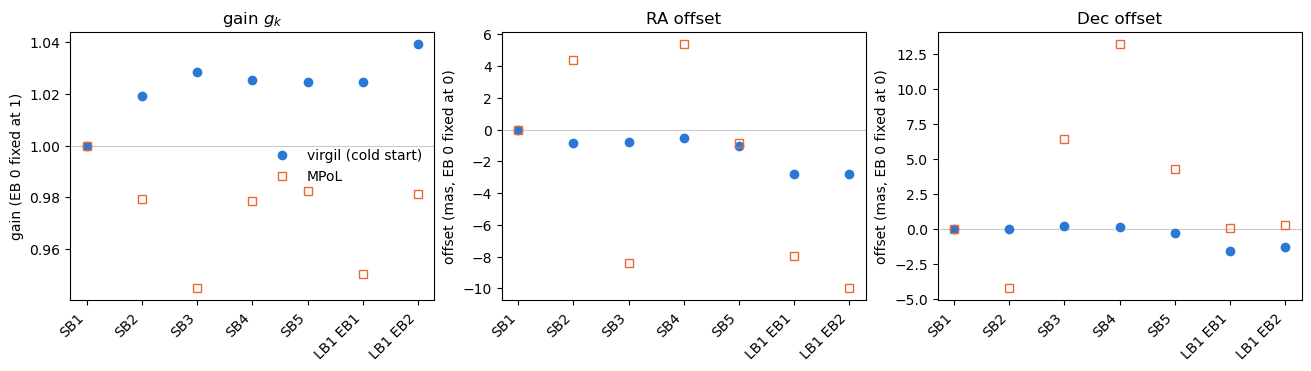

In [3]:
cal = page.cal_arrays(ours, mpol)
k = np.arange(7)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), constrained_layout=True)
for ax, (title, a, b, unit) in zip(axes, [("gain $g_k$", cal["ours"]["gain"], cal["mpol"]["gain"], "gain (EB 0 fixed at 1)"),
                                          ("RA offset", *(cal[s]["offset"][:, 0] for s in ("ours", "mpol")), "offset (mas, EB 0 fixed at 0)"),
                                          ("Dec offset", *(cal[s]["offset"][:, 1] for s in ("ours", "mpol")), "offset (mas, EB 0 fixed at 0)")]):
    ax.plot(k, a, "o", color=page.C_VIRGIL, label="virgil (cold start)")
    ax.plot(k, b, "s", mfc="none", color=page.C_MPOL, label="MPoL")
    ax.set_xticks(k, page.OBS_LABELS, rotation=45, ha="right")
    ax.set_title(title); ax.set_ylabel(unit); ax.axhline(1 if "gain" in title else 0, color="0.8", lw=0.8, zorder=0)
axes[0].legend(frameon=False)
plt.show()

## 4. Fit quality

The usual check for an interferometric fit is a correlation plot of model against data, with error bars on the data and a one-to-one line. We do not make one here, because the 42.4 million visibilities (and the model visibilities that would go with them) live on OzSTAR, and the notebook is limited to the small products the fit saves. What the fit does save is the residual dirty image of each observation: the natural-weighted ($w/s^2$) dirty image of the data minus model, on a 1024² grid of 3 mas pixels, in Jy per dirty beam. If the model captured all the structure, these are noise-like, and any extended residual would show a missing component. Each panel below is one EB, on its own symmetric colour scale (±the 99.5th percentile of |residual| within ±1″), with the rms of that region printed. We have no such maps for MPoL's solution from this run (they come from the `compare` stage with `--data`, which has not been run for it), so this is a check of our fit only. Read the panels as they are: the two long-baseline EBs (17 and 18 µJy/beam) are close to noise-like, but the short-baseline EBs carry smooth, extended residuals at 0.1 to 0.8 mJy/beam, SB1 the largest with a bright central blob, which is expected for unconverged fits to data that also carry flux-scale and offset errors, and which we do not interpret further here.

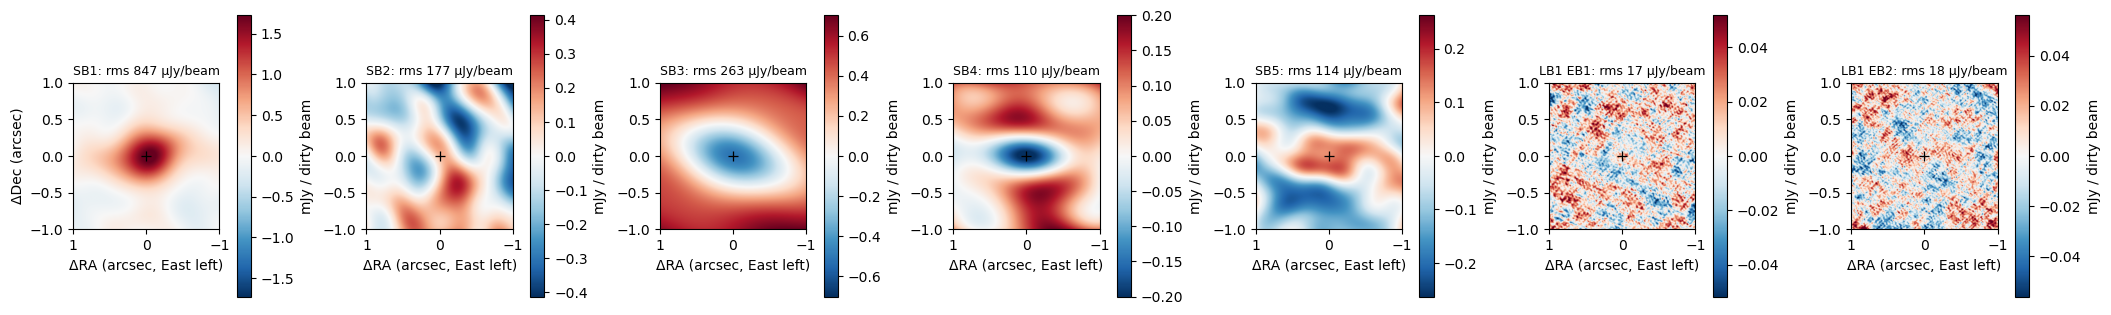

In [4]:
fig, axes = plt.subplots(1, 7, figsize=(21, 3.6), constrained_layout=True)
for e, ax in enumerate(axes):
    r = np.load(ours["dir"] / f"resid_dirty_obs{e}.npy").astype(float)
    g = page.Grid(r.shape[0] // 2, r.shape[0] // 2, 0.003)                   # crosscheck.alma layout: centre at npix // 2, 3 mas
    sig = 1.4826 * np.median(np.abs(r - np.median(r))); c = r.shape[0] // 2
    lim = np.percentile(np.abs(r[c - 340:c + 340, c - 340:c + 340]), 99.5)
    im = ax.imshow(r * 1e3, extent=page.grid_extent(r.shape, g), origin="upper", cmap="RdBu_r", vmin=-lim * 1e3, vmax=lim * 1e3)
    ax.plot(0, 0, "+", color="k", ms=7, mew=0.9)
    ax.set_xlim(1, -1); ax.set_ylim(-1, 1)
    ax.set_title(f"{page.OBS_LABELS[e]}: rms {np.sqrt(np.mean(r[c - 170:c + 170, c - 170:c + 170] ** 2)) * 1e6:.0f} µJy/beam", fontsize=9)
    ax.set_xlabel("ΔRA (arcsec, East left)"); ax.set_ylabel("ΔDec (arcsec)" if e == 0 else "")
    fig.colorbar(im, ax=ax, shrink=0.8, label="mJy / dirty beam")
plt.show()

## 5. Speed

The speed comparison is the objective $R$ against wall-clock time. virgil's fit logs its *loss* (the quantity L-BFGS minimises), which differs from $R$ by a constant, the parts of $-\ln L$ that do not depend on the parameters. `speed.constant_of` takes the constant from the final point of the last stage, $R_\mathrm{final} - \mathrm{loss}_\mathrm{final}$, and we add it to every logged loss. The SB stage (the short-baseline data only, shaded) fits a subset, so its loss is not on the all-data objective and is not drawn on the curve, but its 5,336 s counts in the time, because `speed.fit_curve` accumulates wall time over stages. MPoL's run is known only at the end of its two stages, so it appears as its final objective (horizontal line) and total time of 21,728 s (vertical line). Neither run converged, so this says how fast each reached a given objective, not how fast each finishes.

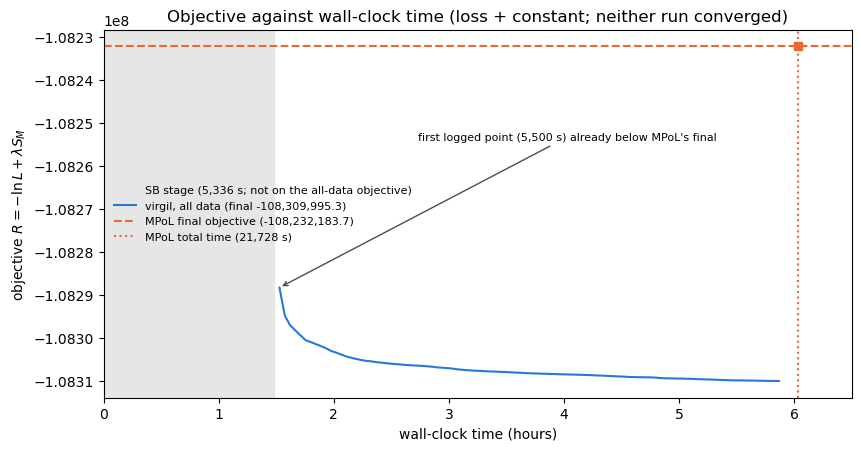

In [5]:
pts, _ = speed.fit_curve(res)
c = speed.constant_of(res)
curve = [dict(t_s=p["t_s"], steps=p["steps"], objective=p["loss"] + c) for p in pts if p["on_curve"]]
target = mo["objective_R"]
hit = speed.time_to(curve, target)
t_mpol = sum(json.loads(f.read_text())["wall_s"] for f in sorted((mpol["dir"]).glob("stage*.time.json")))
sb_end = next(s["wall_s"] for s in res["stages"] if s["name"] == "sb")
fig, ax = plt.subplots(figsize=(8.5, 4.4), constrained_layout=True)
ax.axvspan(0, sb_end / 3600, color="0.9", label=f"SB stage ({sb_end:,.0f} s; not on the all-data objective)")
ax.plot([p["t_s"] / 3600 for p in curve], [p["objective"] for p in curve], color=page.C_VIRGIL, label=f"virgil, all data (final {res['objective_R']:,.1f})")
ax.axhline(target, color=page.C_MPOL, ls="--", label=f"MPoL final objective ({target:,.1f})")
ax.axvline(t_mpol / 3600, color=page.C_MPOL, ls=":", label=f"MPoL total time ({t_mpol:,.0f} s)")
ax.plot(t_mpol / 3600, target, "s", color=page.C_MPOL)
ax.annotate(f"first logged point ({hit['t_first_s']:,.0f} s) already below MPoL's final", (hit["t_first_s"] / 3600, curve[0]["objective"]),
            (0.42, 0.7), textcoords="axes fraction", arrowprops=dict(arrowstyle="->", color="0.3"), fontsize=8)
ax.set_xlim(0, 6.5); ax.set_xlabel("wall-clock time (hours)"); ax.set_ylabel("objective $R = -\\ln L + \\lambda S_M$")
ax.set_title("Objective against wall-clock time (loss + constant; neither run converged)")
ax.legend(frameon=False, fontsize=8, loc="center left")
plt.show()

## Summary

Started cold from a flat Gaussian with no MPoL information, virgil reaches a raw $\chi^2/N$ of 2.7052 against MPoL's 2.7062 and an objective $R$ that is 77,812 lower (−108,309,995.3 against −108,232,183.7). Its all-data objective is below MPoL's final value from the first logged all-data point, at about 5,500 s, against MPoL's 21,728 s in total. Our whole run took 21,134 s, so what this shows is how quickly it got below MPoL's objective, not a shorter run. The two 30 mas-tapered images are visually the same disc, and the plain difference is concentrated at the star and the rings.

The caveats stand. Neither of our stages converged (both hit `max_steps`), so the objective was still falling. The fitted flux differs, 0.243 Jy against 0.294 Jy, and the gains and offsets do not agree: our gains are all above 1 and MPoL's all below, and MPoL's offsets are several times larger. The start used no MPoL information (a 1″ Gaussian, start flux 0.253 Jy, offset bound 100 mas, which did not bind). MPoL's own uniform-start workflow (`R_mpolwf`) failed in our hands and is not shown. MPoL's residual dirty maps and a data–model correlation plot are not available locally, so fit quality is shown for our fit only. The speed comparison sets one program's logged trajectory against another's end-of-stage times, on hardware not matched here (vv#177's speed page has the fairness notes). We do not claim the validation gate as passed: that waits for the image, gain and offset comparison, and for converged fits.